<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS11/datasetPBL/Praktikum2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

In [2]:
# buat sebuah fungsi untuk menampilkan fitting data
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    # plot batas dan margin
    ax.contour(X_grid, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none', edgecolors='k')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

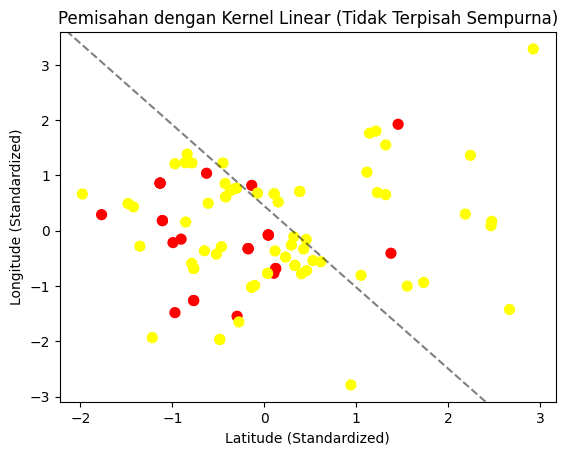

In [3]:
# Load dan gabungkan kedua dataset asli
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

# Ambil 2 kelas utama ('Kafe' vs 'Kedai Kopi') dengan fitur spasial non-linier (latitude, longitude)
df_bin = df_cafes[df_cafes['categories'].isin(["['Kafe']", "['Kedai Kopi']"])].copy()
X = StandardScaler().fit_transform(df_bin[['latitude', 'longitude']].values)
y = (df_bin['categories'] == "['Kedai Kopi']").astype(int).values

# Coba pisahkan dengan kernel linear (terlihat kurang optimal karena sebaran non-linier)
clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False)
plt.xlabel('Latitude (Standardized)')
plt.ylabel('Longitude (Standardized)')
plt.title('Pemisahan dengan Kernel Linear (Tidak Terpisah Sempurna)')
plt.show()

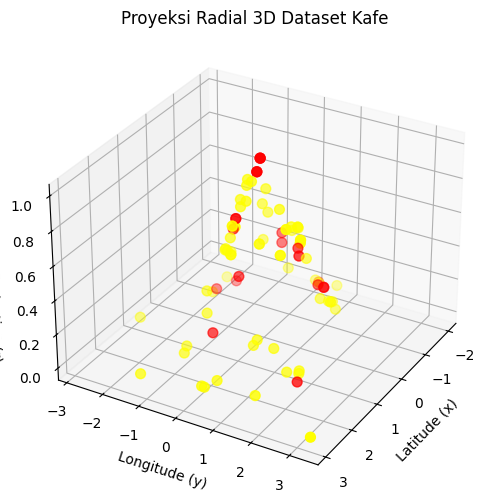

In [4]:
# Hitung proyeksi radial r
r = np.exp(-(X ** 2).sum(1))

from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('Latitude (x)')
    ax.set_ylabel('Longitude (y)')
    ax.set_zlabel('Radial Projection (r)')
    plt.title('Proyeksi Radial 3D Dataset Kafe')
    plt.show()

# Tampilkan langsung plot 3D (dan juga bisa dipanggil via interact di Jupyter)
plot_3D(elev=30, azim=30)

# Opsional jika ingin slider interaktif (pastikan ipywidgets terpasang):
# interact(plot_3D, elev=[-90, 45, 30, 20, 10], azim=(-180, 180), X=fixed(X), y=fixed(y))

In [5]:
clf = SVC(kernel='rbf', C=100)
clf.fit(X, y)

print(f"Akurasi Kernel RBF: {clf.score(X, y) * 100:.2f}%")

Akurasi Kernel RBF: 82.29%


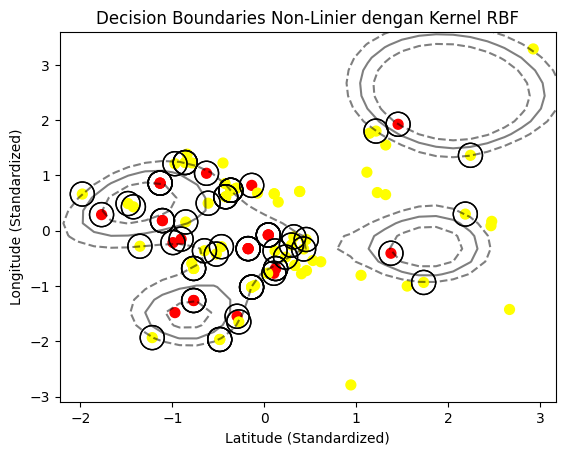

In [6]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none', edgecolors='k')
plt.xlabel('Latitude (Standardized)')
plt.ylabel('Longitude (Standardized)')
plt.title('Decision Boundaries Non-Linier dengan Kernel RBF')
plt.show()